#### ***SubGraph***
-  ***A Subgraph is a reusable workflow inside a larger LangGraph. It groups related nodes into a single component, improving modularity, readability, and maintainability.***

In [1]:
import warnings
warnings.filterwarnings("ignore")

from typing_extensions import TypedDict
from langgraph.graph import StateGraph,START,END 
from langchain_groq import  ChatGroq 
from dotenv import load_dotenv
load_dotenv()

True

In [2]:
class SubState(TypedDict):
    input_text:str 
    translated_text:str

In [3]:
## SubGraph LLM 
LLM = ChatGroq(
    model="llama-3.1-8b-instant",
    temperature=0.3,
    streaming=True
)

In [4]:
def translate_txt(state:SubState):
    prompt = f"""
            Translate the following text to Hindi.
            Keep it natural and clear. Do not add extra content.

            Text:
            {state["input_text"]}
        """.strip()
    translate_txt = LLM.invoke(prompt).content
    return {'translated_text': translate_txt}

In [5]:
## Build SubGraph 
subgraph_build = StateGraph(SubState)
subgraph_build.add_node('translate_text',translate_txt)

subgraph_build.add_edge(START,'translate_text')
subgraph_build.add_edge('translate_text',END)

subgraph = subgraph_build.compile()

In [6]:
# Parent Class 
class State(TypedDict):
    question:str
    english_ans:str 
    hindi_ans:str

In [7]:
llm = ChatGroq(
    model="llama-3.1-8b-instant",
    temperature=0.3,
    streaming=True
)

In [8]:
def generate_answer(state: State):
    answer = llm.invoke(
        f"You are a helpful assistant. Answer clearly.\n\nQuestion: {state['question']}").content
    return {'english_ans': answer}


def translate_answer(state: State):
    # call the subgraph
    result = subgraph.invoke({'input_text': state['english_ans']})
    return {'hindi_ans': result['translated_text']}

In [9]:
parent_builder = StateGraph(State)

parent_builder.add_node("answer", generate_answer)
parent_builder.add_node("translate", translate_answer)

parent_builder.add_edge(START, 'answer')
parent_builder.add_edge('answer', 'translate')
parent_builder.add_edge('translate', END)

graph = parent_builder.compile()

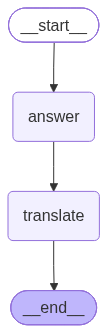

In [10]:
from IPython.display import Image, display
display(Image(graph.get_graph().draw_mermaid_png()))

In [11]:
graph.invoke({'question': 'What is quantum physics'})

{'question': 'What is quantum physics',
 'english_ans': 'Quantum physics, also known as quantum mechanics, is a branch of physics that studies the behavior of matter and energy at an atomic and subatomic level. At these scales, the classical laws of physics no longer apply, and strange, seemingly random phenomena occur.\n\nIn classical physics, objects have definite positions, velocities, and properties. However, in quantum physics, these properties are not fixed until they are measured. Instead, they exist in a state of superposition, where multiple possibilities exist simultaneously. This is known as wave-particle duality, where particles, such as electrons, can exhibit both wave-like and particle-like behavior.\n\nSome key principles of quantum physics include:\n\n1. **Wave-particle duality**: Particles can exhibit both wave-like and particle-like behavior.\n2. **Superposition**: Particles can exist in multiple states simultaneously.\n3. **Entanglement**: Particles can become connec

- ***Code Exmaple To Understand SubGraph***

In [12]:
from typing import TypedDict
class State(TypedDict):
    order:str

In [13]:
# Define node 
def validate(state):
    print("Validating Card")
    return {}

def payment(state):
    print("Payment Success")
    return {}

In [14]:
payment_builder=StateGraph(State)

payment_builder.add_node("validate",validate)
payment_builder.add_node("payment",payment)

payment_builder.add_edge(START,"validate")
payment_builder.add_edge("validate","payment")
payment_builder.add_edge("payment",END)

payment_graph=payment_builder.compile()

In [16]:
builder=StateGraph(State)

builder.add_node("payment",payment_graph)
builder.add_edge(START,"payment")
builder.add_edge("payment",END)
graph=builder.compile()

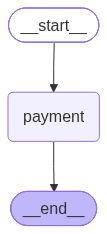

In [17]:
graph